# Persona × comprimento × dropout: análise das 5 métricas

Cada gráfico mostra **métrica × comprimento de contexto**, com uma linha por modelo e IC de 95% (bootstrap).
A linha tracejada marca o **comprimento de treino (4K)**: à esquerda fica o regime ID; à direita, o OOD.

Todas as métricas são **adaptações** (ver `RESULTS.md`). Comparações sempre contra a condição **neutra**,
com os controles **sham** (instrução genérica sem identidade) e **distractor** (outra persona) pelo mesmo pipeline.

Para ver o smoke test, use `TAG = "smoke"` na célula abaixo.

In [ ]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import prepare as P

TAG = None
cfg = P.load_config()
MDIR = P.path(cfg, "metrics") / TAG if TAG else P.path(cfg, "metrics")
S = pd.read_csv(MDIR / "summary.csv")
MODELS = [m["label"] for m in cfg["models"] if m["label"] in set(S.model)]
LENGTHS = sorted(S.length.unique())
TRAIN = cfg["train_length"]
manifest = json.loads(P.path(cfg, "manifest").read_text())
print(f"perfil={cfg['profile']}  modelos={MODELS}  comprimentos={LENGTHS}")

# Paleta categórica validada (ordem fixa; cor segue o modelo) + marcador como codificação secundária
COLORS = dict(zip([m["label"] for m in cfg["models"]], ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
MARKERS = dict(zip([m["label"] for m in cfg["models"]], ["o", "s", "^", "D", "v", "P"]))
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])  # vermelho ← 0 → azul
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 9, "figure.dpi": 110})

COND_PT = {"persona": "persona", "neutral": "neutra", "sham": "sham (controle)", "distractor": "distratora (controle)",
           "contrast": "contraste"}


def get(metric, measure, condition):
    return S[(S.metric == metric) & (S.measure == measure) & (S.condition == condition)]


def lineplot(ax, metric, measure, condition, ref=None):
    d = get(metric, measure, condition)
    for k, m in enumerate(MODELS):
        g = d[d.model == m].sort_values("length")
        if g.empty:
            continue
        x = g.length * 2 ** ((k - (len(MODELS) - 1) / 2) * 0.035)  # deslocamento leve: ICs não se sobrepõem
        err = np.clip(np.nan_to_num([g.value - g.lo, g.hi - g.value]), 0, None)
        ax.errorbar(x, g.value, yerr=err, color=COLORS[m], marker=MARKERS[m], ms=5.5, lw=1.6,
                    elinewidth=1, capsize=0, label=m, markeredgecolor="#fcfcfb", markeredgewidth=0.8)
    ax.axvline(TRAIN, color=MUTED, ls="--", lw=0.9, zorder=0)
    if ref is not None:
        ax.axhline(ref, color=AXIS, lw=1, zorder=0)
    ax.set_xscale("log", base=2)
    ax.set_xticks(LENGTHS, [f"{L // 1024}K" for L in LENGTHS])
    ax.minorticks_off()
    ax.set_xlabel("comprimento do contexto")


def panels(metric, measure, conditions, ylabel, title, ref=None, sharey=True):
    fig, axes = plt.subplots(1, len(conditions), figsize=(3.9 * len(conditions), 3.3), sharey=sharey, squeeze=False)
    for ax, c in zip(axes[0], conditions):
        lineplot(ax, metric, measure, c, ref)
        ax.set_title(COND_PT.get(c, c), loc="left")
    axes[0, 0].set_ylabel(ylabel)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=len(MODELS), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, x=0.01, ha="left", y=1.1, fontsize=12.5, color=INK)
    fig.tight_layout()
    plt.show()


def table(metric, measure, condition, col="value", digits=3):
    d = get(metric, measure, condition)
    return d.pivot_table(index="model", columns="length", values=col).reindex(MODELS).round(digits)

perfil=local  modelos=['WD', 'PN-D-p30', 'PL-D-p30', 'VPAD-p10', 'VPAD-p20', 'VPAD-p30']  comprimentos=[np.int64(4096), np.int64(8192), np.int64(16384)]


## 0. Sanidade: NIAH (V3)

Agulha no palheiro estilo RULER `niah_single_1` (greedy, 20 amostras por comprimento).
Esperado pelo paper: **WD ≈ 0 acima de 4K** e **PL-D-p30 ≈ 100**. Se todos acertassem ou todos errassem,
o backend estaria ignorando o sliding window.

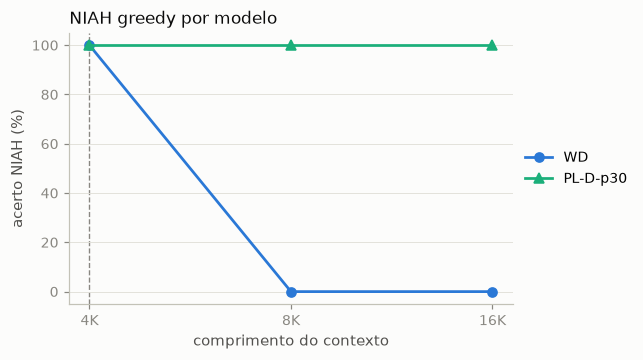

length,4096,8192,16384
model,,,
PL-D-p30,100.0,100.0,100.0
WD,100.0,0.0,0.0


In [ ]:
niah_path = P.path(cfg, "niah")
if niah_path.exists():
    nd = pd.read_json(niah_path, lines=True)
    acc = nd.groupby(["model", "length"]).correct.agg(["mean", "size"]).reset_index()
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    for m in [m for m in COLORS if m in set(acc.model)]:
        g = acc[acc.model == m]
        ax.plot(g.length, 100 * g["mean"], color=COLORS[m], marker=MARKERS[m], ms=6, lw=1.8, label=m)
    ax.axvline(TRAIN, color=MUTED, ls="--", lw=0.9, zorder=0)
    ax.set_xscale("log", base=2); ax.minorticks_off()
    ax.set_xticks(sorted(acc.length.unique()), [f"{L // 1024}K" for L in sorted(acc.length.unique())])
    ax.set_ylim(-5, 105); ax.set_ylabel("acerto NIAH (%)"); ax.set_xlabel("comprimento do contexto")
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5)); ax.set_title("NIAH greedy por modelo", loc="left")
    plt.show()
    display((100 * acc.pivot(index="model", columns="length", values="mean")).round(0))
else:
    print("results/niah.jsonl não encontrado (rode: python src/checks.py v3)")

## 1. Efeito distribucional (adaptação de CoDiTE)

MMD² e Energy distance como **estatísticas U pareadas** (kernel RBF, largura pela mediana) entre os embeddings E5 das respostas
na condição indicada e na neutra. **0 = sem efeito**; quanto maior, mais a condição muda a distribuição das respostas.
Os pares compartilham persona, prompt e seed; o termo cruzado do próprio par é excluído. IC por bootstrap de pares; p-valor por troca dentro do par.

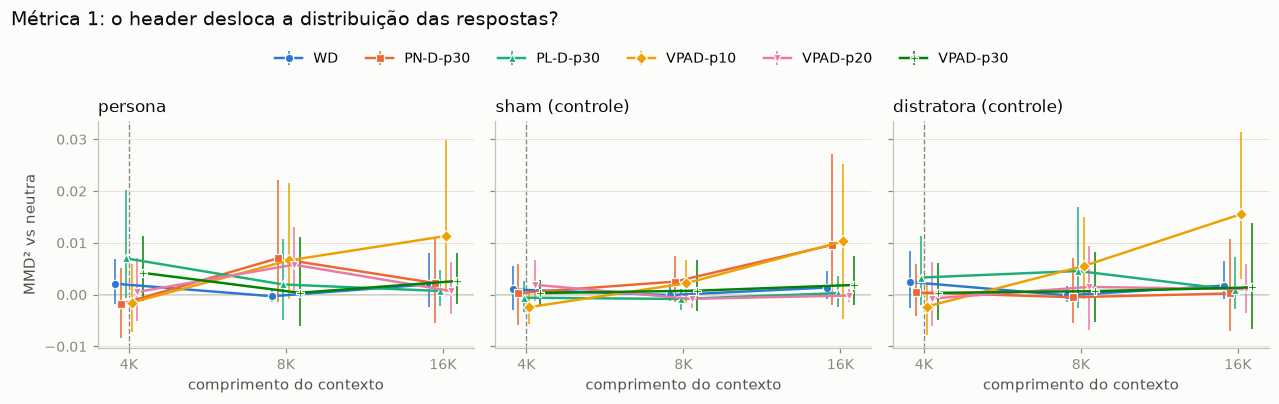

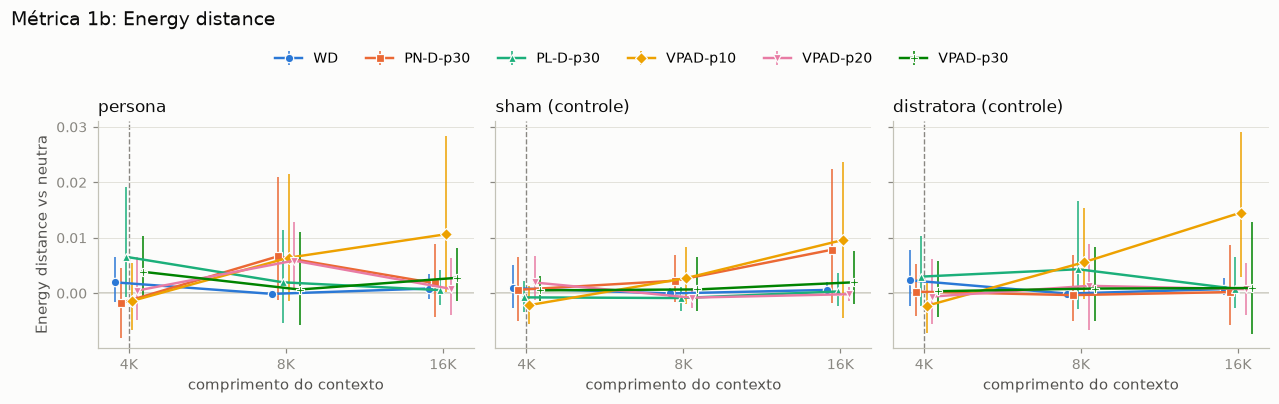

p-valor (permutação) do MMD², persona × neutra:


length,4096,8192,16384
model,,,
WD,0.087,0.809,0.071
PN-D-p30,0.806,0.009,0.165
PL-D-p30,0.010,0.195,0.248
VPAD-p10,0.771,0.022,0.010
VPAD-p20,0.366,0.002,0.304
VPAD-p30,0.013,0.343,0.061


In [ ]:
panels("m1", "mmd2", ["persona", "sham", "distractor"], "MMD² vs neutra",
       "Métrica 1: o header desloca a distribuição das respostas?", ref=0)
panels("m1", "energy", ["persona", "sham", "distractor"], "Energy distance vs neutra",
       "Métrica 1b: Energy distance", ref=0)
print("p-valor (permutação) do MMD², persona × neutra:")
display(table("m1", "mmd2", "persona", col="p"))

## 2. R² vetorial pareado (inspirado em PERMANOVA)

Para cada par (mesma persona, prompt e seed): `d = E(resposta com header) − E(resposta neutra)`.
`R² = n·‖média(d)‖² / Σ‖d‖²` mede quanto das diferenças aponta numa **direção consistente**.
A linha pontilhada cinza é a média do R² sob a hipótese nula (troca aleatória de sinais).
**Não** é porcentagem de variância causal.

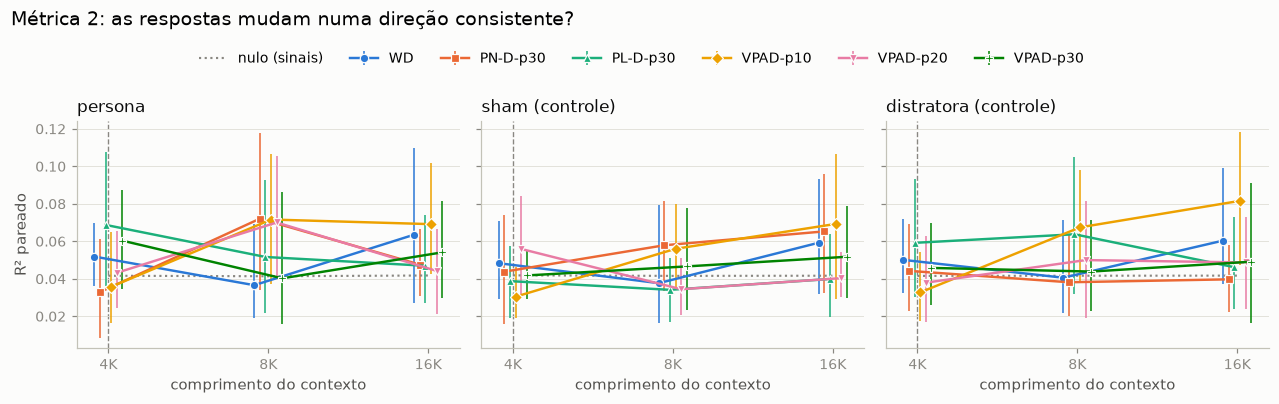

q-valor (Benjamini–Hochberg entre células), persona × neutra:


length,4096,8192,16384
model,,,
WD,0.151,0.807,0.110
PN-D-p30,0.817,0.042,0.259
PL-D-p30,0.042,0.268,0.316
VPAD-p10,0.807,0.042,0.042
VPAD-p20,0.501,0.042,0.501
VPAD-p30,0.042,0.550,0.166


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11.7, 3.3), sharey=True)
for ax, c in zip(axes, ["persona", "sham", "distractor"]):
    lineplot(ax, "m2", "r2", c)
    null = get("m2", "r2_null_mean", c).groupby("length").value.mean()
    ax.plot(null.index, null.values, color=MUTED, ls=":", lw=1.4, label="nulo (sinais)")
    ax.set_title(COND_PT[c], loc="left")
axes[0].set_ylabel("R² pareado")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=len(MODELS) + 1, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Métrica 2: as respostas mudam numa direção consistente?", x=0.01, ha="left", y=1.1, fontsize=12.5)
fig.tight_layout(); plt.show()
print("q-valor (Benjamini–Hochberg entre células), persona × neutra:")
display(table("m2", "r2", "persona", col="p"))

## 3. Escolha contrastiva A/B (adaptação de Contrast Sets)

Margem = logprob(opção da persona) − logprob(outra), média das **duas ordens** de A/B (remove viés de posição).
- **escolhe a opção da persona**: fração de pares com margem > 0. Com o header de **contraste** (1 componente
  invertido), o esperado é cair abaixo de 0,5.
- **sucesso de inversão**: acerta com a persona original **e** com a persona de contraste.

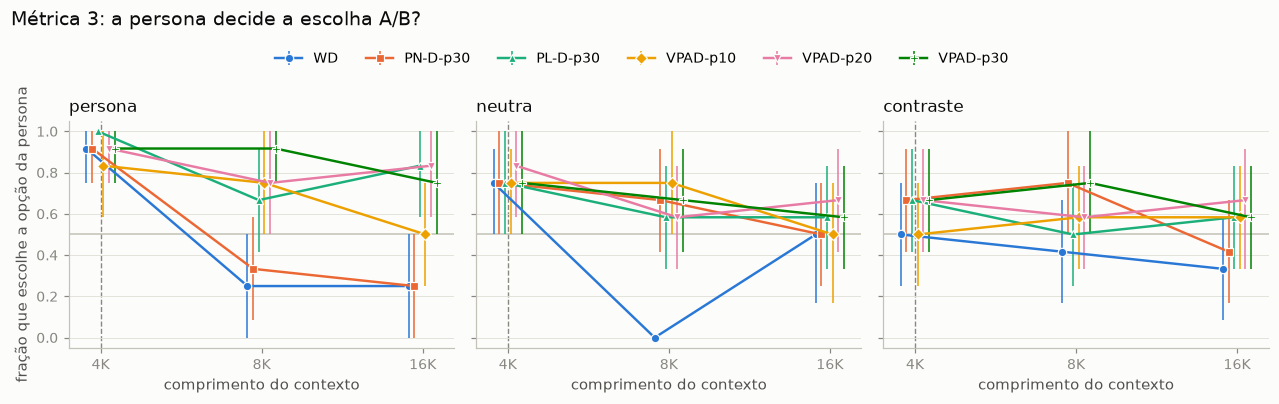

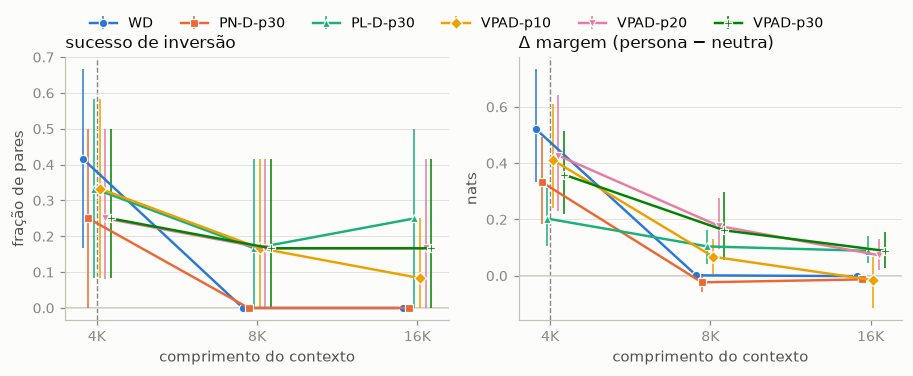

In [ ]:
panels("m3", "picks_persona_option", ["persona", "neutral", "contrast"], "fração que escolhe a opção da persona",
       "Métrica 3: a persona decide a escolha A/B?", ref=0.5)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.3))
lineplot(axes[0], "m3", "flip_success", "contrast", ref=0); axes[0].set_title("sucesso de inversão", loc="left")
axes[0].set_ylabel("fração de pares")
lineplot(axes[1], "m3", "margin_diff_vs_neutral", "persona", ref=0)
axes[1].set_title("Δ margem (persona − neutra)", loc="left"); axes[1].set_ylabel("nats")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=len(MODELS), bbox_to_anchor=(0.5, 1.04)); fig.tight_layout(); plt.show()

## 4. NLI por frase (adaptação de SummaC)

Cada frase da resposta é a premissa; a hipótese é o *claim* (1ª pessoa) da persona para o componente que o pedido
permite expressar. **taxa de apoio** = fração de respostas com alguma frase em entailment > 0,5.
Na condição distratora o claim continua sendo o da persona-alvo, então a expectativa é de apoio baixo.
Ausência de apoio ≠ perda de identidade.

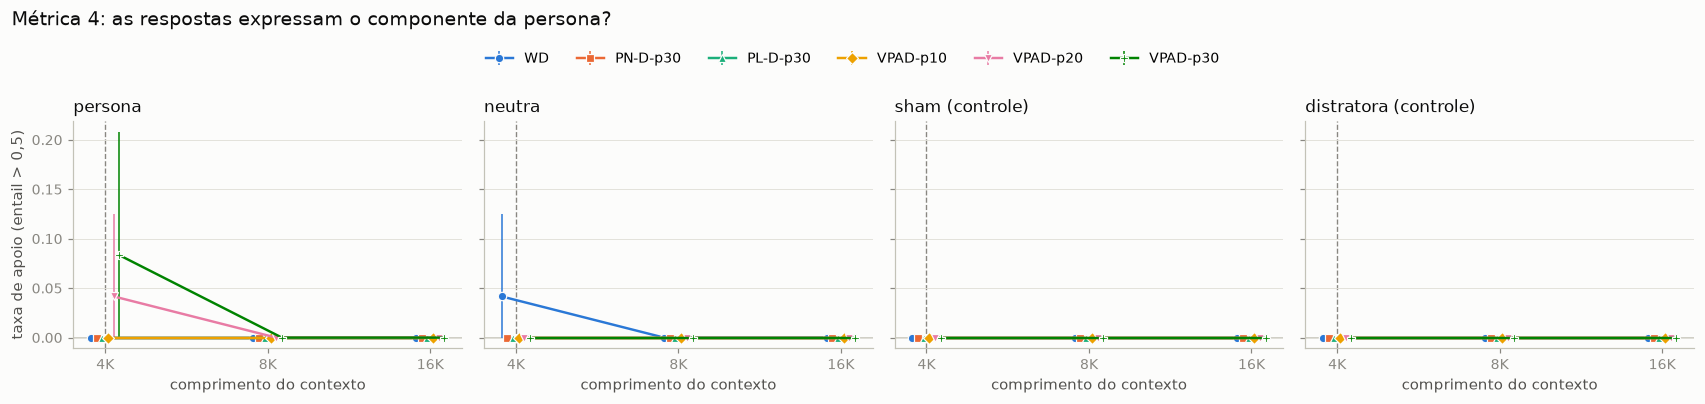

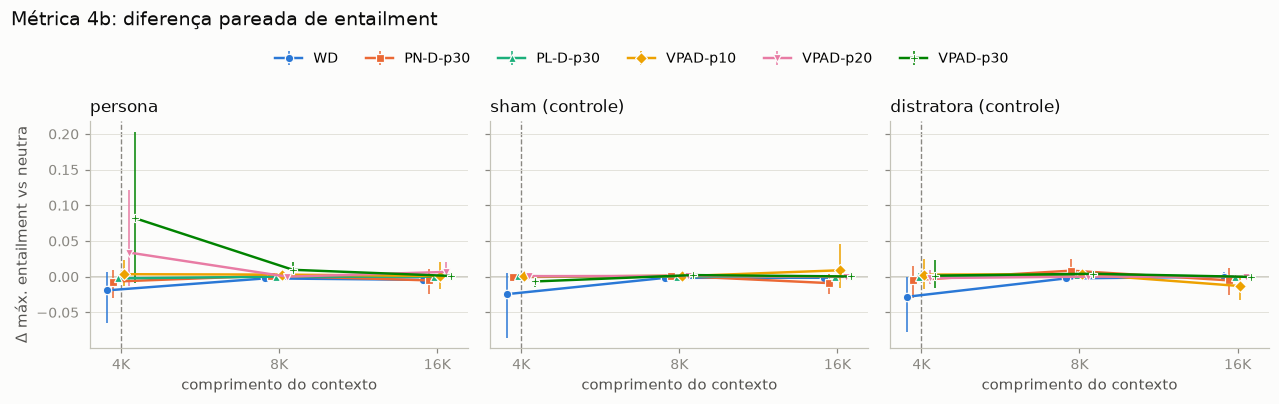

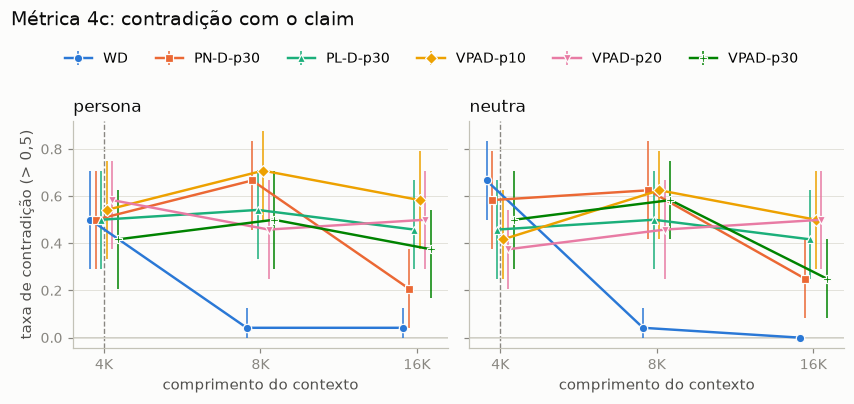

In [ ]:
panels("m4", "support_rate", ["persona", "neutral", "sham", "distractor"], "taxa de apoio (entail > 0,5)",
       "Métrica 4: as respostas expressam o componente da persona?", ref=0)
panels("m4", "entail_diff_vs_neutral", ["persona", "sham", "distractor"], "Δ máx. entailment vs neutra",
       "Métrica 4b: diferença pareada de entailment", ref=0)
panels("m4", "contradiction_rate", ["persona", "neutral"], "taxa de contradição (> 0,5)",
       "Métrica 4c: contradição com o claim", ref=0)

## 5. Recuperação factual (adaptação de QAFactEval)

6 perguntas diretas por persona (greedy, 16 tokens), classificadas por gabarito + aliases em
`correct`, `contradictory` (responde outra coisa) ou `unresolved` (vazia/evasiva).
**cobertura** = 1 − unresolved; **acerto** = correct / total. Mede resposta a pergunta direta, não expressão espontânea.

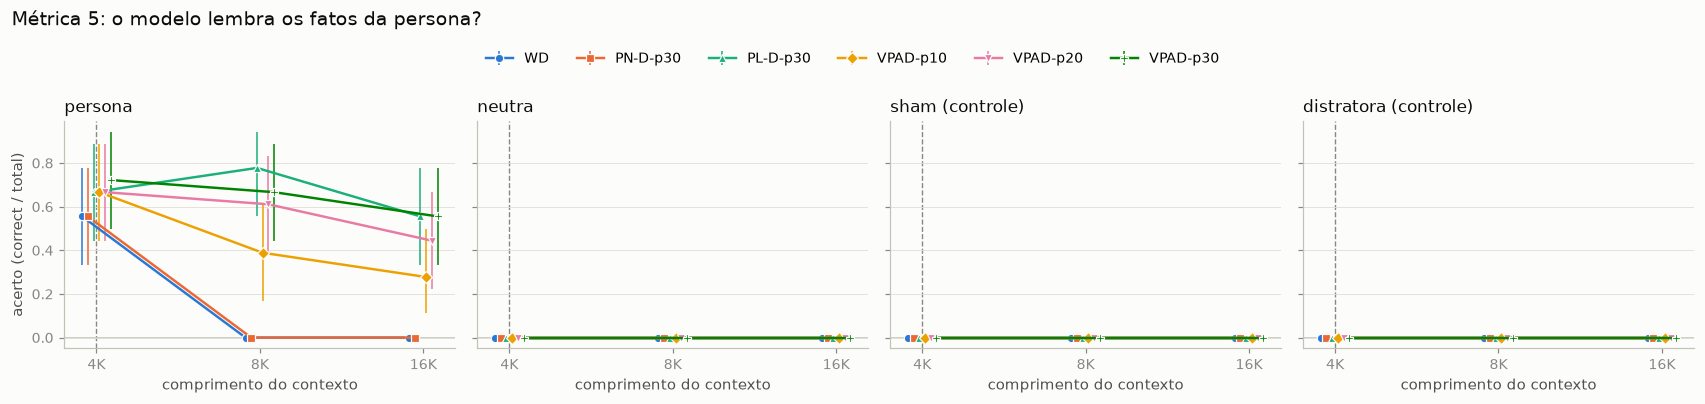

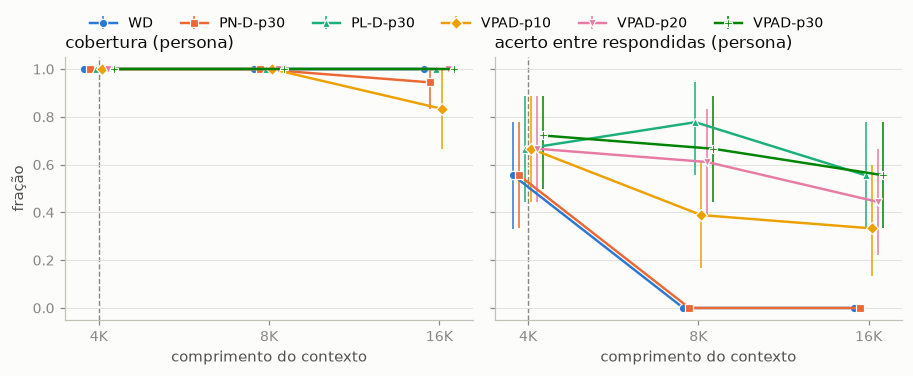

In [ ]:
panels("m5", "correct_rate", ["persona", "neutral", "sham", "distractor"], "acerto (correct / total)",
       "Métrica 5: o modelo lembra os fatos da persona?", ref=0)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.3), sharey=True)
lineplot(axes[0], "m5", "coverage", "persona"); axes[0].set_title("cobertura (persona)", loc="left")
lineplot(axes[1], "m5", "accuracy_answered", "persona"); axes[1].set_title("acerto entre respondidas (persona)", loc="left")
axes[0].set_ylabel("fração")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=len(MODELS), bbox_to_anchor=(0.5, 1.04)); fig.tight_layout(); plt.show()

## 6. Degeneração (dado, não descarte)

Por resposta principal: **vazia**, **truncada** (atingiu `max_tokens` sem `\nUser:`), **degenerada**
(> 50% de 4-gramas repetidos) e **sem texto** (heurística extra: < 50% de tokens com cara de palavra).
`any_bad` = vazia ou degenerada ou sem texto. As métricas 1–4 são calculadas **com** essas respostas.

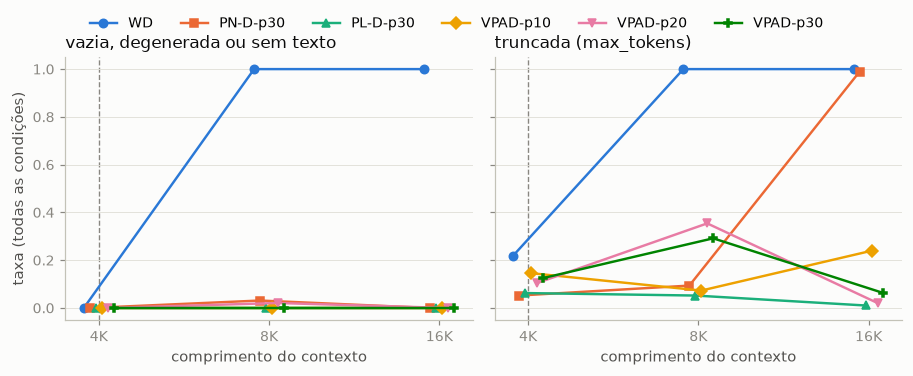

empty  truncated  degenerate  non_text  any_bad
model    length                                                 
WD       4096      0.0       0.22        0.00       0.0     0.00
         8192      0.0       1.00        0.00       1.0     1.00
         16384     0.0       1.00        0.00       1.0     1.00
PN-D-p30 4096      0.0       0.05        0.00       0.0     0.00
         8192      0.0       0.09        0.03       0.0     0.03
         16384     0.0       0.99        0.00       0.0     0.00
PL-D-p30 4096      0.0       0.06        0.00       0.0     0.00
         8192      0.0       0.05        0.00       0.0     0.00
         16384     0.0       0.01        0.00       0.0     0.00
VPAD-p10 4096      0.0       0.15        0.00       0.0     0.00
         8192      0.0       0.07        0.00       0.0     0.00
         16384     0.0       0.24        0.00       0.0     0.00
VPAD-p20 4096      0.0       0.10        0.00       0.0     0.00
         8192      0.0       0.35        0.02       0.0     0.02
         16384     0.0       0.02        0.00       0.0     0.00
VPAD-p30 4096      0.0       0.12        0.00       0.0     0.00
         8192      0.0       0.29        0.00       0.0     0.00
         16384     0.0       0.06        0.00       0.0     0.00

In [ ]:
deg = pd.read_csv(MDIR / "degeneration.csv")
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.3), sharey=True)
for ax, meas, t in zip(axes, ["any_bad", "truncated"], ["vazia, degenerada ou sem texto", "truncada (max_tokens)"]):
    for k, m in enumerate(MODELS):
        g = deg[deg.model == m].groupby("length")[meas].mean()
        ax.plot(g.index * 2 ** ((k - 2.5) * 0.035), g.values, color=COLORS[m], marker=MARKERS[m], ms=5.5, lw=1.6, label=m)
    ax.axvline(TRAIN, color=MUTED, ls="--", lw=0.9, zorder=0)
    ax.set_xscale("log", base=2); ax.minorticks_off(); ax.set_xticks(LENGTHS, [f"{L // 1024}K" for L in LENGTHS])
    ax.set_title(t, loc="left"); ax.set_xlabel("comprimento do contexto")
axes[0].set_ylabel("taxa (todas as condições)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=len(MODELS), bbox_to_anchor=(0.5, 1.04)); fig.tight_layout(); plt.show()
display(deg.groupby(["model", "length"])[["empty", "truncated", "degenerate", "non_text", "any_bad"]].mean()
        .reindex(MODELS, level=0).round(2))

## 7. Painel-resumo: modelo × comprimento

Uma célula por modelo × comprimento para as medidas principais (condição persona).
Diferenças contra a neutra usam escala divergente (azul = a favor da persona, vermelho = contra, cinza = 0).

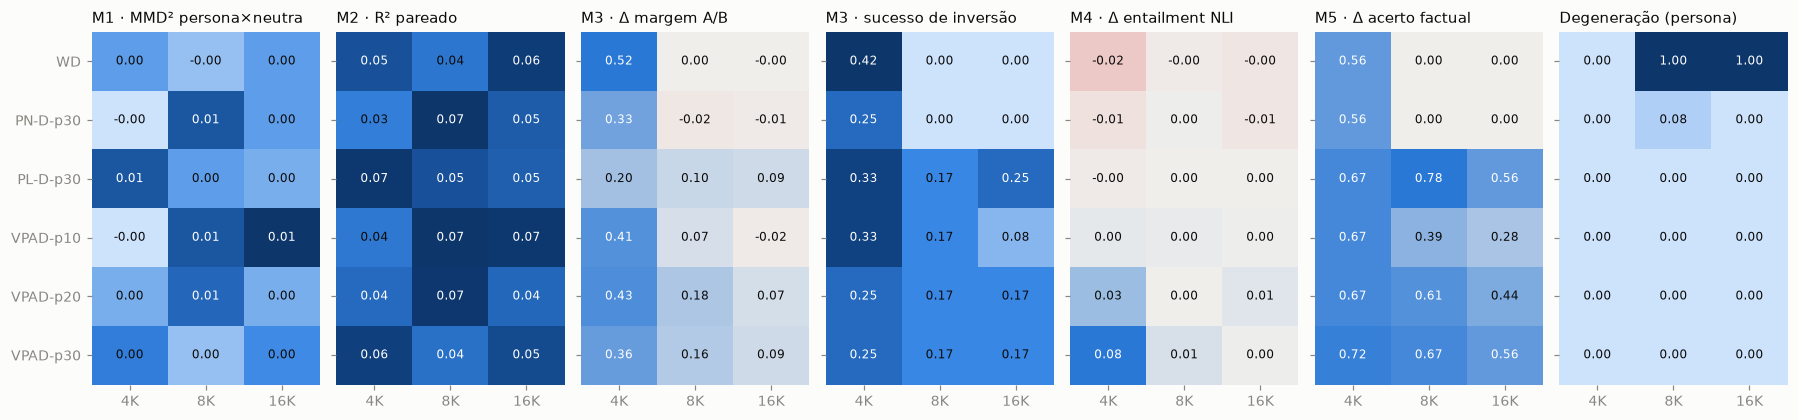

In [ ]:
KEY = [("m1", "mmd2", "persona", "M1 · MMD² persona×neutra", "seq"),
       ("m2", "r2", "persona", "M2 · R² pareado", "seq"),
       ("m3", "margin_diff_vs_neutral", "persona", "M3 · Δ margem A/B", "div"),
       ("m3", "flip_success", "contrast", "M3 · sucesso de inversão", "seq"),
       ("m4", "entail_diff_vs_neutral", "persona", "M4 · Δ entailment NLI", "div"),
       ("m5", "correct_diff_vs_neutral", "persona", "M5 · Δ acerto factual", "div"),
       ("degeneration", "any_bad", "persona", "Degeneração (persona)", "seq")]
fig, axes = plt.subplots(1, len(KEY), figsize=(2.35 * len(KEY), 0.42 * len(MODELS) + 1.4), sharey=True)
for ax, (met, meas, cond, title, kind) in zip(axes, KEY):
    t = table(met, meas, cond)
    v = t.to_numpy(float)
    if kind == "div":
        lim = np.nanmax(np.abs(v)) or 1
        norm, cmap = TwoSlopeNorm(0, -lim, lim), DIV
    else:
        norm, cmap = plt.Normalize(min(0, np.nanmin(v)), np.nanmax(v) or 1), SEQ
    ax.imshow(v, cmap=cmap, norm=norm, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if not np.isnan(v[i, j]):
                dark = kind == "seq" and norm(v[i, j]) > 0.55 or kind == "div" and abs(norm(v[i, j]) - 0.5) > 0.3
                ax.text(j, i, f"{v[i, j]:.2f}", ha="center", va="center", fontsize=8, color="#ffffff" if dark else INK)
    ax.set_xticks(range(len(t.columns)), [f"{L // 1024}K" for L in t.columns])
    ax.set_yticks(range(len(t.index)), t.index); ax.grid(False)
    ax.set_title(title, loc="left", fontsize=9.5)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout(); plt.show()

## 8. ID (4K) × OOD (≥ 8K)

Valor no comprimento de treino, média nos comprimentos OOD e a variação (OOD − ID), por modelo.

In [ ]:
rows = []
for met, meas, cond, title, _ in KEY:
    d = get(met, meas, cond)
    for m in MODELS:
        g = d[d.model == m]
        idv, oodv = g[g.length == TRAIN].value.mean(), g[g.length > TRAIN].value.mean()
        rows.append({"medida": title, "modelo": m, "ID (4K)": idv, "OOD (≥8K)": oodv, "Δ OOD−ID": oodv - idv})
ido = pd.DataFrame(rows).set_index(["medida", "modelo"]).round(3)
display(ido)

ID (4K)  OOD (≥8K)  Δ OOD−ID
medida                   modelo                                
M1 · MMD² persona×neutra WD          0.002      0.001    -0.001
                         PN-D-p30   -0.002      0.005     0.006
                         PL-D-p30    0.007      0.001    -0.006
                         VPAD-p10   -0.002      0.009     0.010
                         VPAD-p20    0.001      0.003     0.003
                         VPAD-p30    0.004      0.001    -0.003
M2 · R² pareado          WD          0.052      0.050    -0.002
                         PN-D-p30    0.033      0.060     0.027
                         PL-D-p30    0.069      0.049    -0.019
                         VPAD-p10    0.036      0.070     0.035
                         VPAD-p20    0.043      0.057     0.014
                         VPAD-p30    0.060      0.047    -0.013
M3 · Δ margem A/B        WD          0.521      0.000    -0.521
                         PN-D-p30    0.333     -0.018    -0.352
                         PL-D-p30    0.203      0.096    -0.107
                         VPAD-p10    0.411      0.026    -0.385
                         VPAD-p20    0.427      0.125    -0.302
                         VPAD-p30    0.359      0.125    -0.234
M3 · sucesso de inversão WD          0.417      0.000    -0.417
                         PN-D-p30    0.250      0.000    -0.250
                         PL-D-p30    0.333      0.208    -0.125
                         VPAD-p10    0.333      0.125    -0.208
                         VPAD-p20    0.250      0.167    -0.083
                         VPAD-p30    0.250      0.167    -0.083
M4 · Δ entailment NLI    WD         -0.019     -0.003     0.016
                         PN-D-p30   -0.007     -0.002     0.005
                         PL-D-p30   -0.002      0.000     0.002
                         VPAD-p10    0.004      0.002    -0.002
                         VPAD-p20    0.034      0.003    -0.030
                         VPAD-p30    0.082      0.005    -0.077
M5 · Δ acerto factual    WD          0.556      0.000    -0.556
                         PN-D-p30    0.556      0.000    -0.556
                         PL-D-p30    0.667      0.667     0.000
                         VPAD-p10    0.667      0.333    -0.333
                         VPAD-p20    0.667      0.528    -0.139
                         VPAD-p30    0.722      0.611    -0.111
Degeneração (persona)    WD          0.000      1.000     1.000
                         PN-D-p30    0.000      0.042     0.042
                         PL-D-p30    0.000      0.000     0.000
                         VPAD-p10    0.000      0.000     0.000
                         VPAD-p20    0.000      0.000     0.000
                         VPAD-p30    0.000      0.000     0.000

## 9. Controles: persona × sham × distratora

Se o efeito for específico da persona, ele deve aparecer na persona e não no sham. A distratora muda a distribuição
(M1/M2) mas não deve apoiar os claims/fatos da persona-alvo (M4/M5).

In [ ]:
ctrl = []
for met, meas, label in [("m1", "mmd2", "M1 MMD²"), ("m2", "r2", "M2 R²"), ("m4", "support_rate", "M4 apoio"),
                         ("m5", "correct_rate", "M5 acerto")]:
    for cond in ["persona", "sham", "distractor"] + (["neutral"] if met in ("m4", "m5") else []):
        d = get(met, meas, cond)
        for _, r in d.iterrows():
            ctrl.append({"medida": label, "condição": COND_PT[cond], "model": r.model, "length": r.length, "value": r.value})
ctrl = pd.DataFrame(ctrl)
display(ctrl.pivot_table(index=["medida", "condição"], columns="length", values="value", aggfunc="mean").round(3))
print("(média entre os modelos; por modelo: ctrl.pivot_table(index=['medida','condição','model'], columns='length'))")

length                           4096   8192   16384
medida    condição                                  
M1 MMD²   distratora (controle)  0.001  0.002  0.003
          persona                0.002  0.004  0.003
          sham (controle)        0.000  0.001  0.004
M2 R²     distratora (controle)  0.045  0.051  0.054
          persona                0.049  0.057  0.054
          sham (controle)        0.043  0.044  0.054
M4 apoio  distratora (controle)  0.000  0.000  0.000
          neutra                 0.007  0.000  0.000
          persona                0.021  0.000  0.000
          sham (controle)        0.000  0.000  0.000
M5 acerto distratora (controle)  0.000  0.000  0.000
          neutra                 0.000  0.000  0.000
          persona                0.639  0.407  0.306
          sham (controle)        0.000  0.000  0.000

(média entre os modelos; por modelo: ctrl.pivot_table(index=['medida','condição','model'], columns='length'))


## 10. Reprodutibilidade

Revisões fixadas (modelos, dataset, E5, NLI), SHA-256 do filler e versões das bibliotecas, de `results/manifest.json`.

In [ ]:
print(json.dumps({k: manifest[k] for k in ("models", "filler", "embeddings", "nli", "environment", "seed")
                  if k in manifest}, indent=1, ensure_ascii=False)[:4000])
err = pd.read_csv(MDIR / "errors.csv") if (MDIR / "errors.csv").stat().st_size > 1 else pd.DataFrame()
print(f"\nfalhas registradas na coleta: {len(err)}")

{
 "models": [
  {
   "id": "vapavlo/SmolLM3-SWA-WD",
   "label": "WD",
   "revision": "4f090d3480f95d9b73c30da63a5828dd48eca8b6"
  },
  {
   "id": "vapavlo/SmolLM3-SWA-pre-norm-p30",
   "label": "PN-D-p30",
   "revision": "724ade59f4ef5fc8093d1d45c50664f7161052d5"
  },
  {
   "id": "vapavlo/SmolLM3-SWA-pre-linear-p30",
   "label": "PL-D-p30",
   "revision": "c31e966d9efe3f89f2ed049910d7862c5ce91fb4"
  },
  {
   "id": "vapavlo/SmolLM3-SWA-VPAD-p10",
   "label": "VPAD-p10",
   "revision": "c54671ccaef8305822776b27aabbc80f53b400b5"
  },
  {
   "id": "vapavlo/SmolLM3-SWA-VPAD-p20",
   "label": "VPAD-p20",
   "revision": "0843d7c6bbbf5f9ad6d982976560ed44062de9b1"
  },
  {
   "id": "vapavlo/SmolLM3-SWA-VPAD-p30",
   "label": "VPAD-p30",
   "revision": "109e2bae0e8ec25b138d7e80f7f492c2bcef15d3"
  }
 ],
 "filler": {
  "dataset": "HuggingFaceH4/ultrachat_200k",
  "revision": "8049631c405ae6576f93f445c6b8166f76f5505a",
  "file": "data/train_sft-00000-of-00003-a3ecf92756993583.parquet",
  "seed"